### 1. Download and Prepare the IMDB Dataset

In [ ]:
import os
import tarfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
import re
import string

# Download original Stanford Large Movie Review Dataset (IMDb)
!wget -q http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz -O aclImdb_v1.tar.gz

print("Extracting dataset...")
with tarfile.open('aclImdb_v1.tar.gz', 'r:gz') as tar:
    tar.extractall()

# Load reviews from extracted folders
def load_reviews_from_dir(base_dir):
    reviews = []
    labels = []
    for label_type in ['pos', 'neg']:
        dir_name = os.path.join(base_dir, label_type)
        for fname in os.listdir(dir_name):
            if fname.endswith('.txt'):
                with open(os.path.join(dir_name, fname), 'r', encoding='utf-8') as f:
                    reviews.append(f.read())
                labels.append('positive' if label_type == 'pos' else 'negative')
    return pd.DataFrame({'review': reviews, 'sentiment': labels})

print("Processing files into a DataFrame...")
train_data = load_reviews_from_dir('aclImdb/train')
test_data = load_reviews_from_dir('aclImdb/test')

# Combine to represent original 50k dataset
df = pd.concat([train_data, test_data], ignore_index=True)
print(f"Dataset successfully loaded! Shape: {df.shape}")
display(df.head())

Extracting dataset...


/tmp/ipykernel_346/2161452936.py:17: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Processing files into a DataFrame...
Dataset successfully loaded! Shape: (50000, 2)


,review,sentiment
0,This movie is not only the funniest film ever ...,positive
1,George Lopez is a funny man even without the s...,positive
2,"Well, I thoroughly enjoyed this movie. It was ...",positive
3,I am not going to spoil the contents to anyone...,positive
4,****SPOILERS**** Powerhouse movie that shows h...,positive


### 2. Preprocessing & Text Cleaning

In [ ]:
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
nltk.download('punkt')

stop_words = set(stopwords.words('english'))

def clean_text(text):
    # Remove HTML tags
    text = re.sub(r'<[^>]*>', '', text)
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation and numbers
    text = re.sub(f"[{re.escape(string.punctuation)}]", "", text)
    text = re.sub(r'\d+', '', text)
    # Remove stopwords
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return " ".join(words)

# Apply cleaning
df['clean_review'] = df['review'].apply(clean_text)
df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# Split into Train, Validation, and Test sets
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
train_df, val_df = train_test_split(train_df, test_size=0.1, random_state=42, stratify=train_df['label'])

print(f"Train size: {len(train_df)}, Val size: {len(val_df)}, Test size: {len(test_df)}")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Train size: 36000, Val size: 4000, Test size: 10000


### 3. Model 1: Logistic Regression (TF-IDF Baseline)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Vectorize text
vectorizer = TfidfVectorizer(max_features=10000)
X_train_tfidf = vectorizer.fit_transform(train_df['clean_review'])
X_test_tfidf = vectorizer.transform(test_df['clean_review'])
y_train = train_df['label'].values
y_test = test_df['label'].values

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Evaluate
lr_preds = lr_model.predict(X_test_tfidf)
print(classification_report(y_test, lr_preds))


              precision    recall  f1-score   support

           0       0.89      0.89      0.89      5000
           1       0.89      0.89      0.89      5000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### 4. Model 2: LSTM Sentiment Classifier

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenization and Padding
max_vocab = 20000
max_len = 200

tokenizer = Tokenizer(num_words=max_vocab, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df['clean_review'])

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(train_df['clean_review']), maxlen=max_len, padding='post', truncating='post')
X_val_seq = pad_sequences(tokenizer.texts_to_sequences(val_df['clean_review']), maxlen=max_len, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(test_df['clean_review']), maxlen=max_len, padding='post', truncating='post')

y_train_seq = train_df['label'].values
y_val_seq = val_df['label'].values
y_test_seq = test_df['label'].values

# Build LSTM Model
lstm_model = tf.keras.Sequential([
    tf.keras.layers.Embedding(max_vocab, 128, input_length=max_len),
    tf.keras.layers.SpatialDropout1D(0.2),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=False)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

lstm_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train Model
history = lstm_model.fit(
    X_train_seq, y_train_seq,
    epochs=3,
    batch_size=64,
    validation_data=(X_val_seq, y_val_seq),
    verbose=1
)

# Evaluate LSTM
lstm_probs = lstm_model.predict(X_test_seq)
lstm_preds = (lstm_probs > 0.5).astype(int).flatten()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 45s 50ms/step - accuracy: 0.8279 - loss: 0.3860 - val_accuracy: 0.8867 - val_loss: 0.3018
Epoch 2/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 26s 44ms/step - accuracy: 0.9202 - loss: 0.2152 - val_accuracy: 0.8845 - val_loss: 0.2872
Epoch 3/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 28s 21ms/step - accuracy: 0.9505 - loss: 0.1443 - val_accuracy: 0.8730 - val_loss: 0.3704
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


### 5. Model 3: Vanilla Transformer

In [ ]:
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = tf.keras.layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(ff_dim, activation="relu"),
            tf.keras.layers.Dense(embed_dim),
        ])
        self.layernorm1 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = tf.keras.layers.Dropout(rate)
        self.dropout2 = tf.keras.layers.Dropout(rate)

    def call(self, inputs, training=True):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

class TokenAndPositionEmbedding(tf.keras.layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super().__init__()
        self.token_emb = tf.keras.layers.Embedding(input_dim=vocab_size, output_dim=embed_dim)
        self.pos_emb = tf.keras.layers.Embedding(input_dim=maxlen, output_dim=embed_dim)

    def call(self, x):
        maxlen = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=maxlen, delta=1)
        positions = self.pos_emb(positions)
        x = self.token_emb(x)
        return x + positions

# Build Vanilla Transformer network
embed_dim = 64
num_heads = 4
ff_dim = 64

inputs = tf.keras.layers.Input(shape=(max_len,))
embedding_layer = TokenAndPositionEmbedding(max_len, max_vocab, embed_dim)
x = embedding_layer(inputs)
transformer_block = TransformerBlock(embed_dim, num_heads, ff_dim)
x = transformer_block(x)
x = tf.keras.layers.GlobalAveragePooling1D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
x = tf.keras.layers.Dense(20, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

transformer_model = tf.keras.Model(inputs=inputs, outputs=outputs)
transformer_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

# Train model
transformer_model.fit(
    X_train_seq, y_train_seq,
    epochs=3,
    batch_size=64,
    validation_data=(X_val_seq, y_val_seq),
    verbose=1
)

trans_probs = transformer_model.predict(X_test_seq)
trans_preds = (trans_probs > 0.5).astype(int).flatten()


Epoch 1/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 32s 37ms/step - accuracy: 0.7892 - loss: 0.4203 - val_accuracy: 0.8770 - val_loss: 0.2929
Epoch 2/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9210 - loss: 0.2119 - val_accuracy: 0.8860 - val_loss: 0.2744
Epoch 3/3
563/563 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9491 - loss: 0.1482 - val_accuracy: 0.8842 - val_loss: 0.3193
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step


### 6. Model 4: Pretrained BERT Model (DistilBERT for Efficiency)

In [ ]:
!pip install -q transformers datasets torch
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Use PyTorch version of DistilBERT for reliable inference
model_name = "distilbert-base-uncased-finetuned-sst-2-english"
transformers_tokenizer = AutoTokenizer.from_pretrained(model_name)
bert_model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Tokenize test set
subset_test = test_df.sample(200, random_state=42) # Smaller subset for faster execution on free CPU/GPU
inputs_bert = transformers_tokenizer(subset_test['review'].tolist(), padding=True, truncation=True, max_length=256, return_tensors="pt")

# Get Predictions
with torch.no_grad():
    outputs = bert_model(**inputs_bert)
    b_logits = outputs.logits
    bert_preds = torch.argmax(b_logits, dim=-1).cpu().numpy()

y_test_bert = subset_test['label'].values

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

### 7. Comparative Performance Analysis

,Accuracy,Precision,Recall,F1
Logistic Regression,0.8903,0.886819,0.89480,0.890791
LSTM,0.8726,0.831967,0.93380,0.879947
Vanilla Transformer,0.8823,0.903015,0.85660,0.879195
BERT (DistilBERT),0.8900,0.935484,0.84466,0.887755


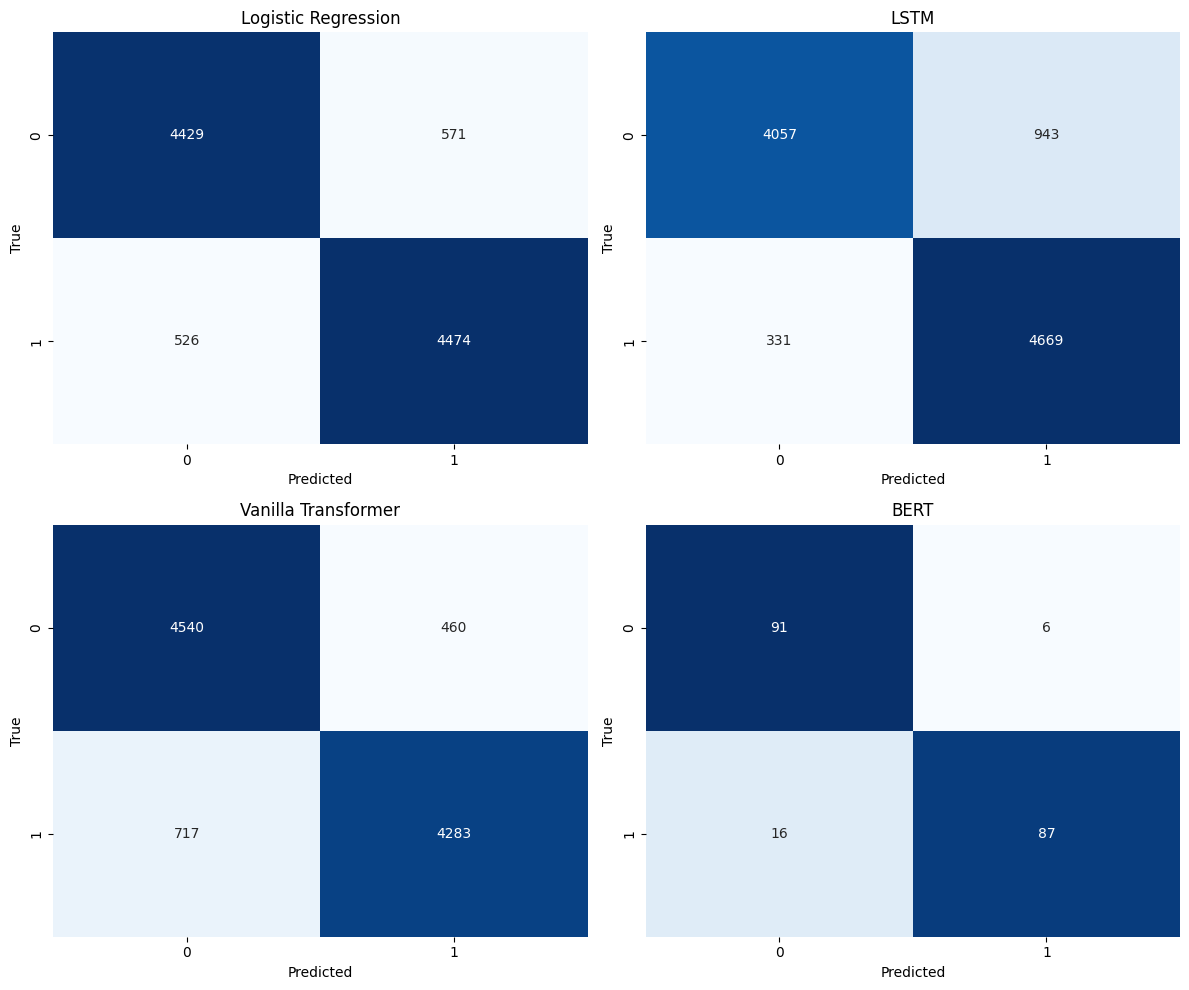

In [ ]:
models_metrics = {}

# Helper to register metrics
def add_metrics(name, y_true, y_pred):
    models_metrics[name] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred)
    }

# Register evaluations
add_metrics('Logistic Regression', y_test, lr_preds)
add_metrics('LSTM', y_test_seq, lstm_preds)
add_metrics('Vanilla Transformer', y_test_seq, trans_preds)
add_metrics('BERT (DistilBERT)', y_test_bert, bert_preds)

metrics_df = pd.DataFrame(models_metrics).T
display(metrics_df)

# Plot Confusion Matrices side-by-side
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
plots = [
    (y_test, lr_preds, "Logistic Regression", axes[0, 0]),
    (y_test_seq, lstm_preds, "LSTM", axes[0, 1]),
    (y_test_seq, trans_preds, "Vanilla Transformer", axes[1, 0]),
    (y_test_bert, bert_preds, "BERT", axes[1, 1])
]

for y_t, y_p, title, ax in plots:
    cm = confusion_matrix(y_t, y_p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.tight_layout()
plt.show()
